<a href="https://colab.research.google.com/github/furalmiqbadi/PembelajaranMesin_01_AbdulGhofurAlmiqbadi/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Persiapan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

In [ ]:
df = pd.read_csv('CC_Customer_Dataset.csv')
display(df.head())
df.info()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


## Seleksi Fitur

In [ ]:
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
        'Total_visits_online', 'Total_calls_made']]

## No 1. Scatterplot

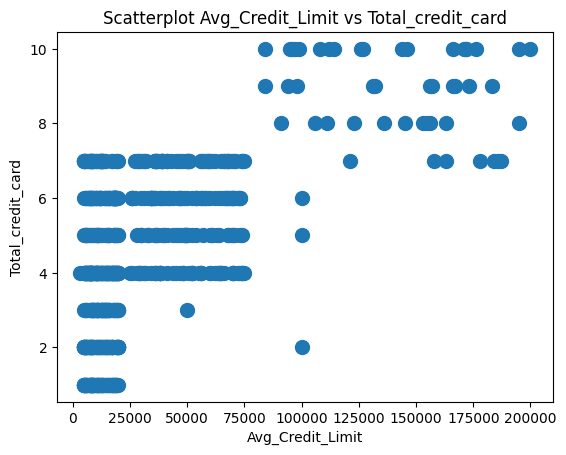

In [ ]:
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_credit_card')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.title('Scatterplot Avg_Credit_Limit vs Total_credit_card')
plt.show()

Tidak linier karena titik data mengelompok dan tidak membuat garis lurus.

## No 2. Elbow Method untuk Menentukan k Terbaik

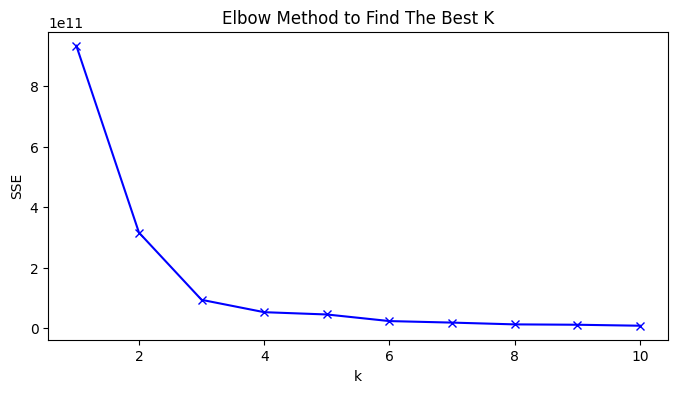

In [ ]:
sse = []
K = range(1, 11)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method to Find The Best K')
plt.show()

Dari linechart SSE itu terdapat penurunan tajam terjadi sampai k=3 lalu melandai setelahnya. Titik tekuk atau elbow inilah yang dipilih dan bukan SSE terkecil karena SSE memang selalu menurun seiring bertambahnya k.

## No 3. Model K-Means & Scatterplot

In [ ]:
cl_kmeans = KMeans(n_clusters=3, random_state=42)
y_kmeans = cl_kmeans.fit_predict(X)

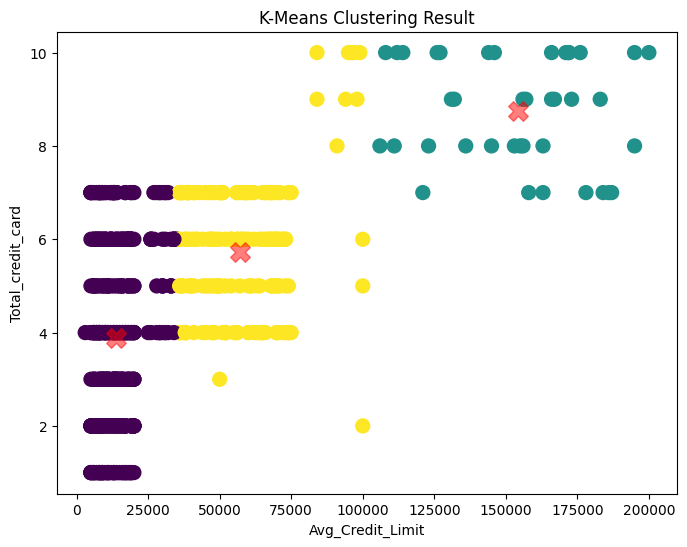

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)

centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5, marker='X')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_credit_card')
plt.title('K-Means Clustering Result')
plt.show()

## No 4. Model DBSCAN

In [ ]:
X_scaled = StandardScaler().fit_transform(X)

dbscan = DBSCAN(eps=0.7, min_samples=3)
cluster_db = dbscan.fit_predict(X_scaled)

## No 5. Menentukan jumlah k terbaik Optimal DBSCAN

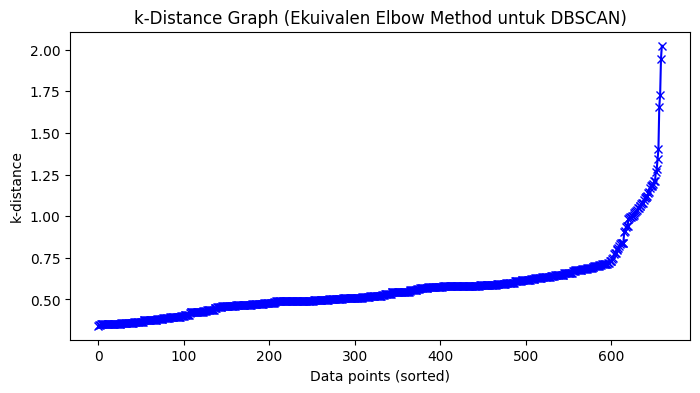

In [ ]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, -1], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(distances, 'bx-')
plt.xlabel('Data points (sorted)')
plt.ylabel('k-distance')
plt.title('k-Distance Graph (Ekuivalen Elbow Method untuk DBSCAN)')
plt.show()

In [ ]:
for eps_val in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    for min_s in [3, 5, 8]:
        db = DBSCAN(eps=eps_val, min_samples=min_s)
        labels = db.fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise = (labels == -1).sum() / len(labels) * 100
        if n_clusters >= 2 and noise < 20:
            print(f"eps={eps_val}, min_samples={min_s} >> clusters={n_clusters}, noise={noise:.2f}%")

eps=0.5, min_samples=3 >> clusters=22, noise=15.45%
eps=0.6, min_samples=3 >> clusters=10, noise=7.73%
eps=0.6, min_samples=5 >> clusters=8, noise=12.42%
eps=0.7, min_samples=3 >> clusters=3, noise=6.97%
eps=0.8, min_samples=3 >> clusters=6, noise=3.18%
eps=0.8, min_samples=5 >> clusters=2, noise=6.67%


DBSCAN tidak pakai k seperti K-Means, jadi elbow method diganti k-distance graph. Dengan mencari titik di mana grafik mulai naik tajam maka di situ kepadatan cluster berakhir dan noise mulai muncul. Nilai eps di titik itulah yang dipilih, lalu dicek lewat trial supaya noise tidak berlebihan dan cluster tetap ≥ 2.

## No 6. Silhouette Score & DBI DBSCAN

In [ ]:
mask = cluster_db != -1
if len(set(cluster_db[mask])) > 1:
    sil = silhouette_score(X_scaled[mask], cluster_db[mask])
    dbi = davies_bouldin_score(X_scaled[mask], cluster_db[mask])
    print(f'Silhouette Score: {sil}')
    print(f'Davies-Bouldin Index: {dbi}')
else:
    print('Cluster terbentuk kurang dari 2, atur ulang eps/min_samples.')

noise_ratio = np.sum(cluster_db == -1) / len(cluster_db) * 100
print(f'Persentase noise: {noise_ratio:.2f}%')

Silhouette Score: 0.4901386085163051
Davies-Bouldin Index: 0.6992988436403974
Persentase noise: 6.97%
